# ЛР 6. Логистическая регрессия
Якименко Владислав, №16 и Пахомов Игнат, №8 · P3313

Titanic: прогноз `Survived`. Веса обучаются градиентным спуском и методом Ньютона.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

cwd = Path.cwd()
lab = next(p for p in (cwd, cwd / 'lab_6') if (p / 'lab6_logistic.py').is_file())
sys.path.insert(0, str(lab))
from lab6_logistic import ROOT, FEATURES, run, sigmoid, log_loss

data = pd.read_csv(ROOT / 'data/titanic.csv')
display(data[FEATURES + ['Survived']].head())
display(data.isna().sum().rename('Пропуски').to_frame())
display(data[FEATURES + ['Survived']].describe().T.round(3))

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


,Пропуски
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


,count,mean,std,min,25%,50%,75%,max
Pclass,891.0,2.309,0.836,1.00,2.000,3.000,3.0,3.000
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329
Survived,891.0,0.384,0.487,0.00,0.000,0.000,1.0,1.000


## Обучение и выбор настройки
Параметры предобработки считаются на обучающей части. Сначала выбираем модель и порог по validation, затем оцениваем все настройки на одном test.

In [2]:
results, experiment = run()
columns = ['method', 'rate', 'iterations', 'validation_f1', 'test_accuracy',
           'test_precision', 'test_recall', 'test_f1', 'train_log_loss']
display(results[columns].round(4))
print('Настройка по validation:', experiment['selected'])
display(pd.DataFrame({
    'Порог 0.5': experiment['test_at_0_5'],
    f"Порог {experiment['threshold']:.4f} по validation": experiment['test_at_selected_threshold'],
    'Базовый прогноз класса 0': experiment['test_majority_baseline'],
}).T.round(4))

,method,rate,iterations,validation_f1,test_accuracy,test_precision,test_recall,test_f1,train_log_loss
0,gradient,0.01,10,0.7778,0.8090,0.7656,0.7206,0.7424,0.6807
1,gradient,0.01,50,0.7552,0.8034,0.7619,0.7059,0.7328,0.6386
2,gradient,0.01,200,0.7465,0.7978,0.7500,0.7059,0.7273,0.5496
3,gradient,0.10,10,0.7465,0.8034,0.7619,0.7059,0.7328,0.5987
4,gradient,0.10,50,0.7591,0.8034,0.7619,0.7059,0.7328,0.4889
5,gradient,0.10,200,0.7519,0.8146,0.7869,0.7059,0.7442,0.4527
6,gradient,1.00,10,0.7612,0.8090,0.7742,0.7059,0.7385,0.4616
7,gradient,1.00,50,0.7463,0.8090,0.7742,0.7059,0.7385,0.4484
8,gradient,1.00,200,0.7556,0.7921,0.7541,0.6765,0.7132,0.4476
9,newton,0.01,10,0.7612,0.7978,0.7500,0.7059,0.7273,0.6548


Настройка по validation: {'method': 'gradient', 'rate': 0.01, 'iterations': 10}


,accuracy,precision,recall,f1
Порог 0.5,0.8090,0.7656,0.7206,0.7424
Порог 0.5021 по validation,0.7978,0.7857,0.6471,0.7097
Базовый прогноз класса 0,0.6180,0.0000,0.0000,0.0000


## Графики
Усы статистики показывают минимум и максимум. Кривые потерь рассчитаны на train, график порогов построен на validation. На матрицах ошибок строки соответствуют фактическим классам, столбцы — прогнозам.

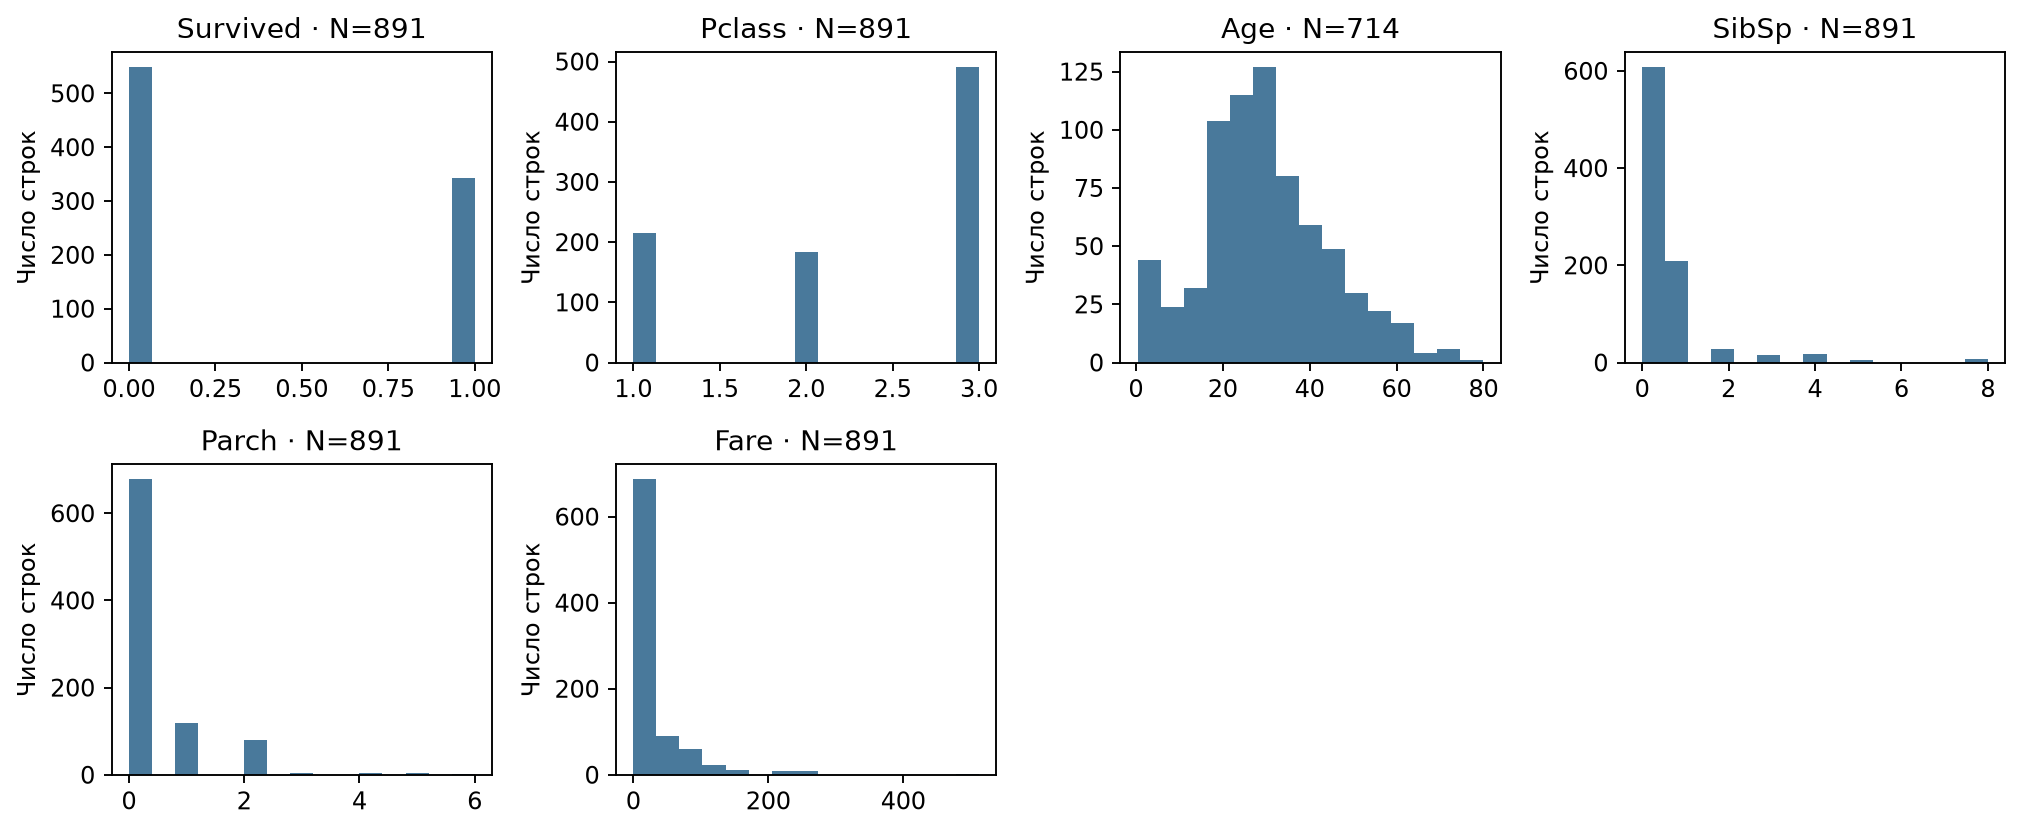

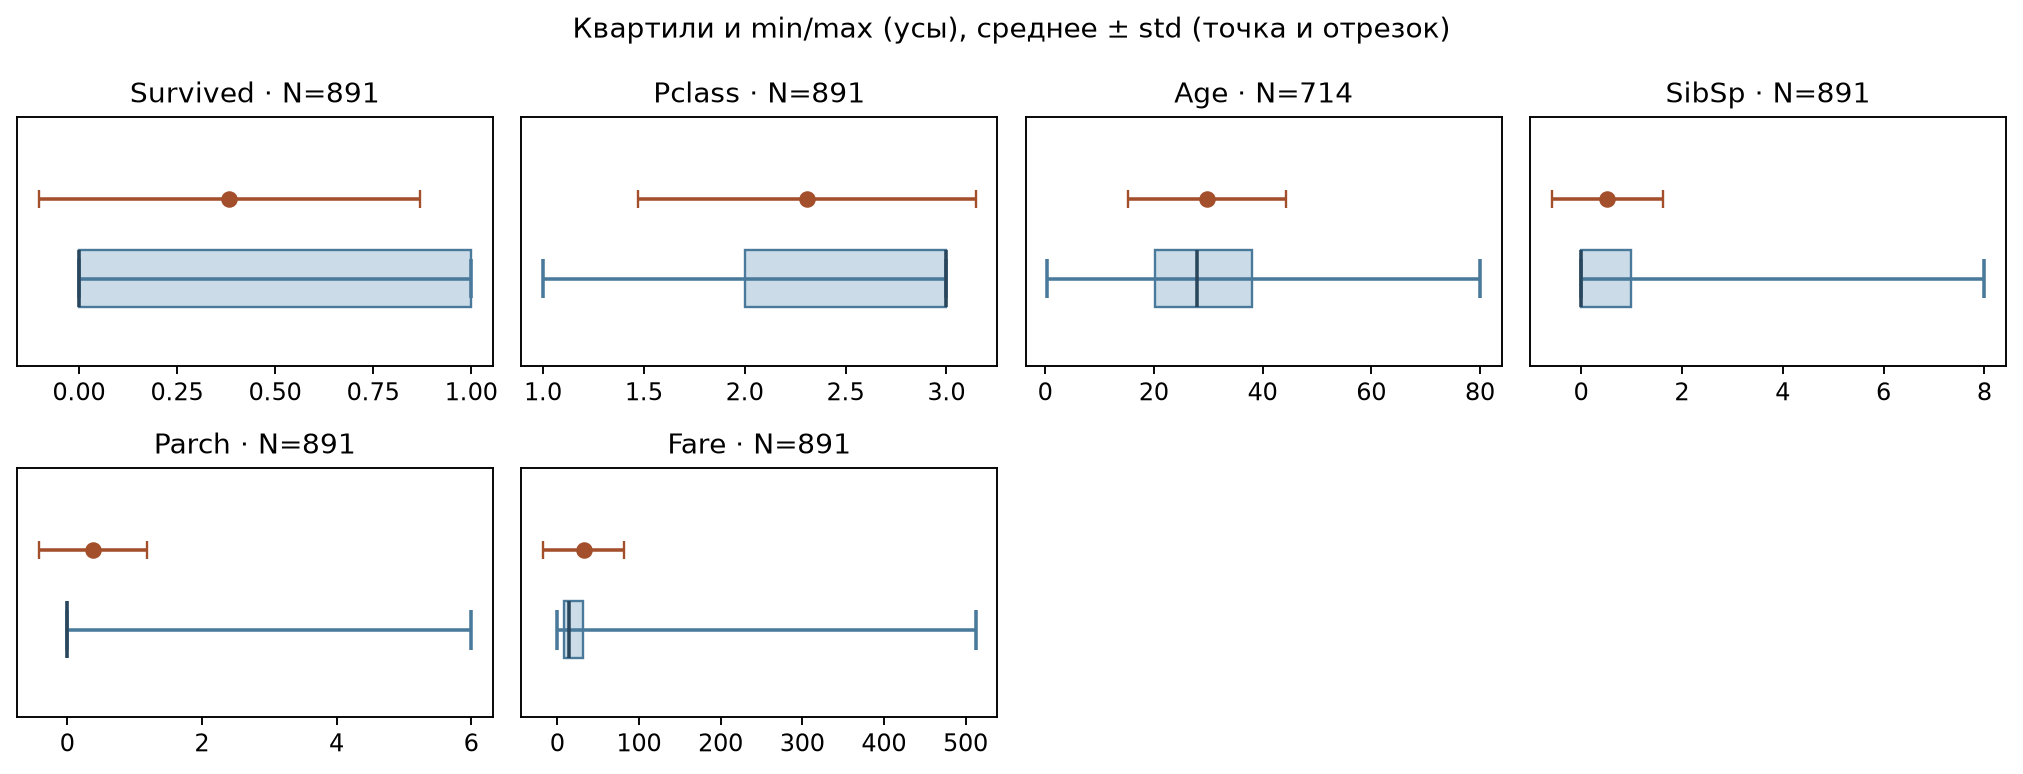

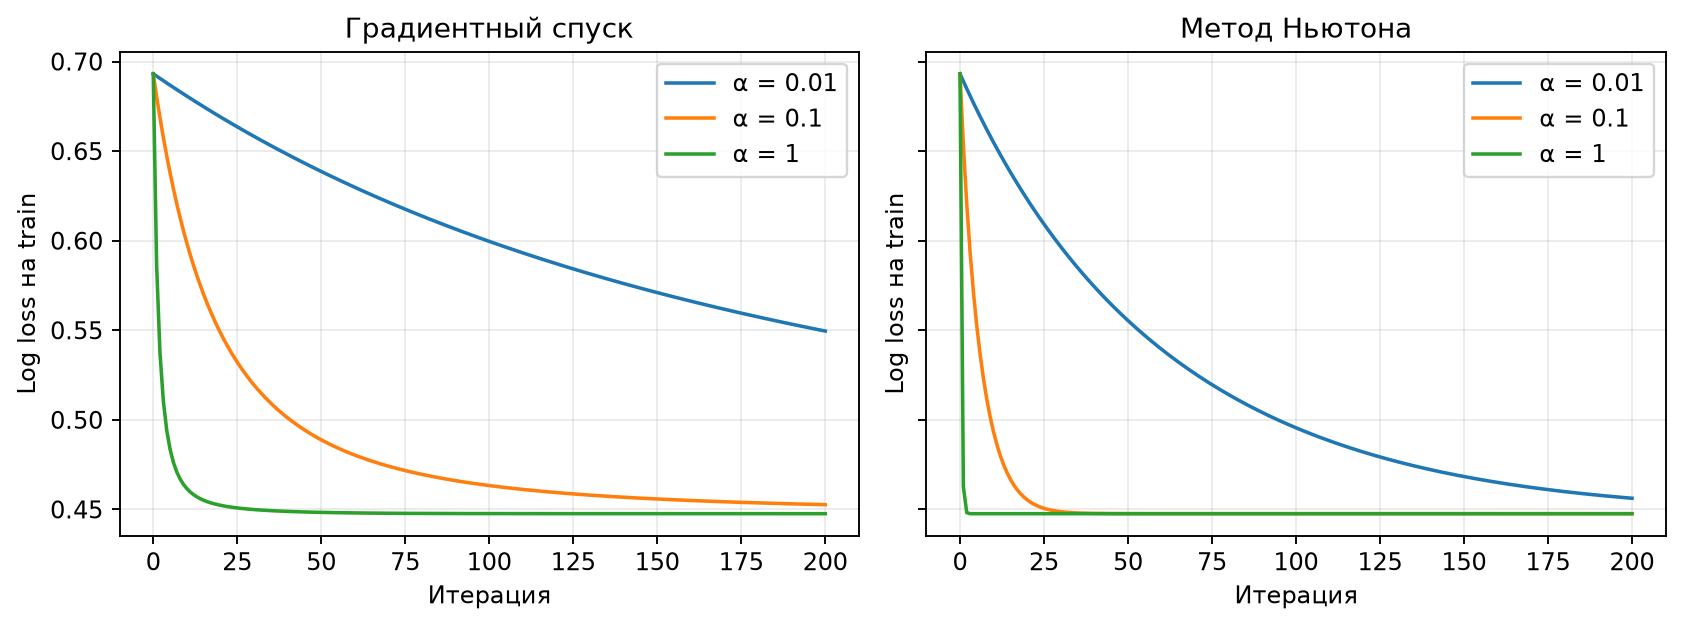

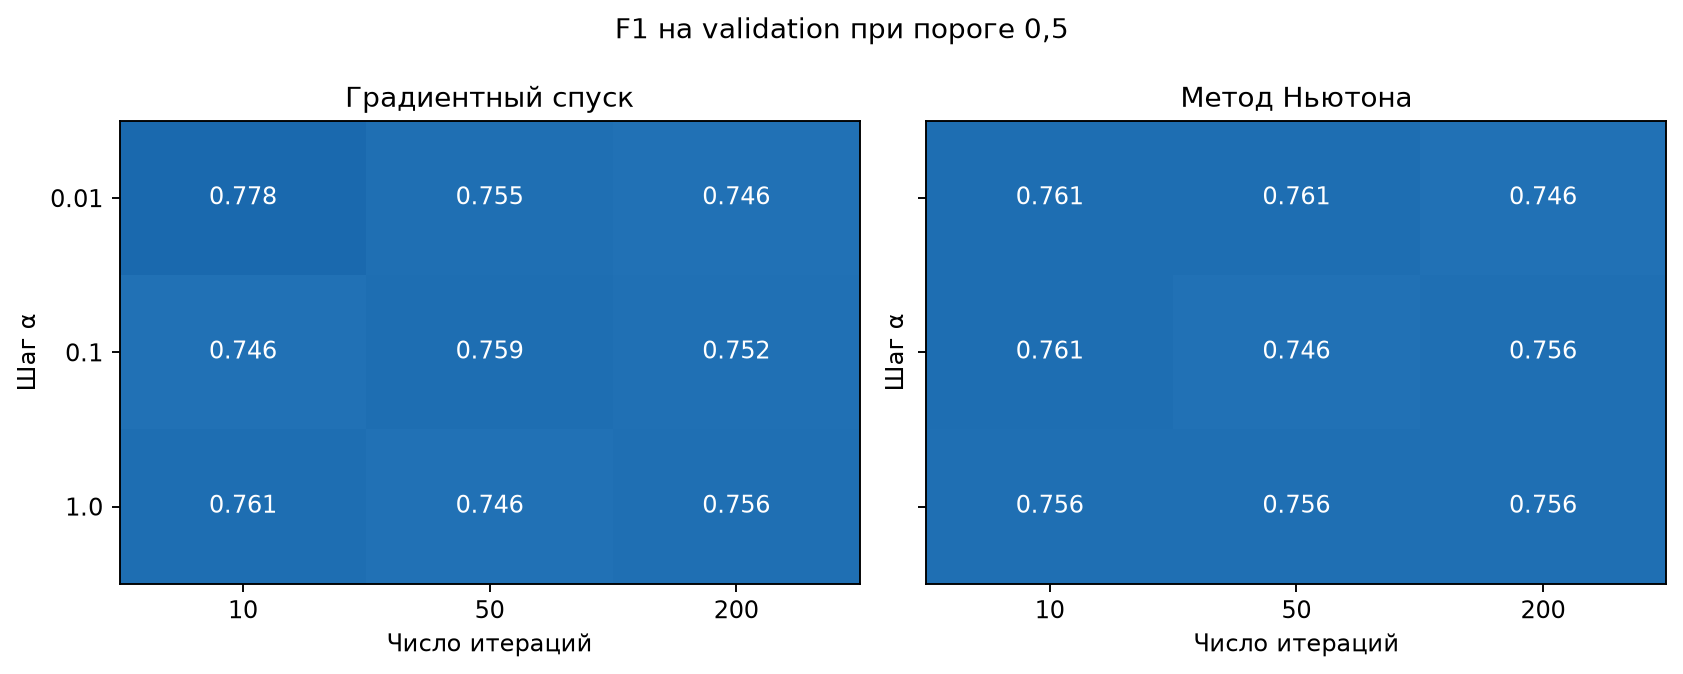

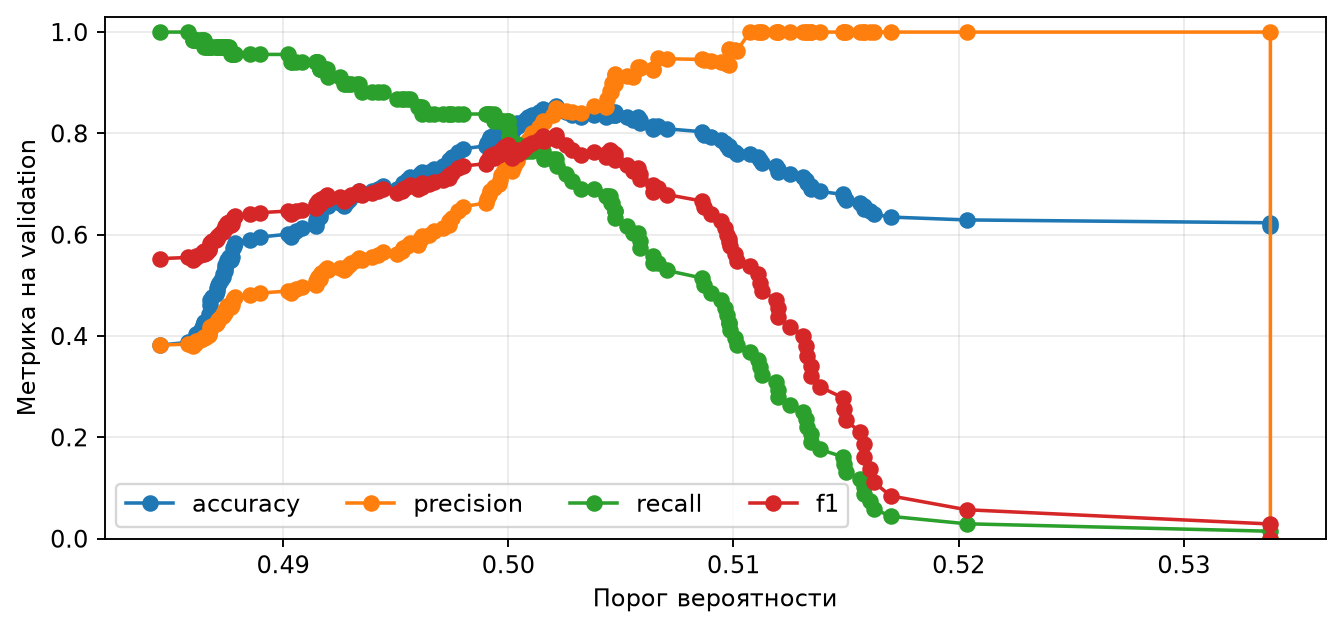

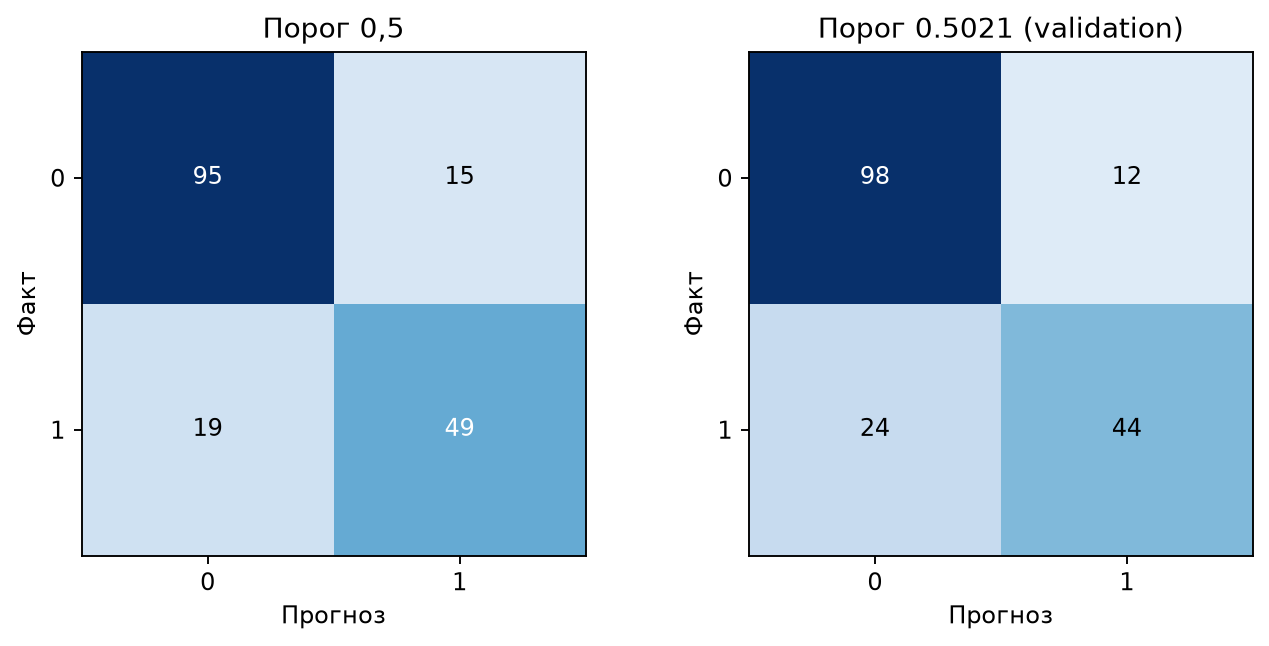

,feature,coefficient
0,intercept,-0.01144
1,Pclass=2,0.00414
2,Pclass=3,-0.01429
3,Sex=male,-0.02562
4,Age,-0.00422
5,SibSp,-0.00213
6,Parch,0.00519
7,Fare,0.01180
8,Embarked=Q,0.00027
9,Embarked=S,-0.00710


In [3]:
figures = ROOT / 'results/figures'
for image in sorted(figures.glob('*.png')):
    display(Image(filename=str(image), width=940))
display(pd.read_csv(ROOT / 'results/coefficients.csv').round(5))

## Вывод
Ньютон быстрее снижает log loss по числу итераций. Снижение обучающей потери и рост F1 на тесте могут расходиться. На этом разбиении отобранный по validation порог повысил Precision на test и снизил Recall и F1.